# Junk Food Multi-class Classification - Vision Encoder (Colab / Local)

Classifies every frame into exactly one **ad type** (`tip`) of `tip-multiclass-dataset.zip` (`tip_multiclass_dataset.csv`
+ `images/`): non-ad, food brand, food promoted by a non-food company, supermarket promoting / not promoting food, and
restaurant promoting / not promoting food. A pretrained vision backbone feeds a softmax classification head trained with
class-weighted cross-entropy. Runs on Google Colab (dataset in Google Drive) or locally (dataset in `./dataset`).

## Training Flow

Run the notebook top to bottom.

1. **Setup cell** - detects Colab vs local, installs missing packages, mounts Drive and extracts the dataset.
2. **Data cells** - load and validate the CSV and build the group-aware stratified train/val/test split (set `PILOT = True` for a fast ~20% subset).
3. **Machinery cells** - define backbones, the classification head, training and evaluation. Nothing executes here.
4. **Experiment cell** - trains the `BACKBONE` selected in the backbone-config cell. `FINETUNE = True` warms up the head on frozen embeddings and then fine-tunes the top of the backbone; `FINETUNE = False` trains only the head on frozen embeddings. Early stopping uses validation macro-F1; the test split is used once at the end.
5. **Curves, examples and export** - training curves, a few test predictions and `runs/cnn/` (downloaded as a zip on Colab).

To compare backbones, change `BACKBONE` and re-run from the backbone-config cell.

## Environment Setup (Colab or Local)

Run the setup cell below **first**. It auto-detects Google Colab and, when running there, installs missing
dependencies, mounts Google Drive and extracts the dataset zip onto the local Colab disk (much faster than reading
thousands of JPEGs over Drive). Pretrained weights are downloaded fresh each session.

**Colab checklist**
1. `Runtime > Change runtime type > GPU` (T4 is enough; A100/L4 are faster).
2. Upload `tip-multiclass-dataset.zip` (from `unhealthy-dataset-generator`; it contains `tip_multiclass_dataset.csv` and `images/`) to Drive.
3. Add a Colab Secret (key icon in the left sidebar) named `MULTICLASS_DATASET_ZIP_PATH` with the path of that `.zip`, either absolute (`/content/drive/MyDrive/datasets/tip-multiclass-dataset.zip`) or relative to `/content/drive` (`MyDrive/datasets/tip-multiclass-dataset.zip`), enable notebook access, then run all cells.

Locally the dataset is read from `./dataset` (the extracted zip; override with the `JUNK_FOOD_DATASET_DIR` environment variable).

In [1]:
# =====================================================================
# ENVIRONMENT SETUP - runs on Google Colab and locally.
#
# Colab:  installs missing packages, mounts Google Drive and extracts the
#         dataset zip to the local disk.
# Local:  no-op besides resolving ./dataset .
# =====================================================================
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))

CSV_NAME = "tip_multiclass_dataset.csv"
IMAGES_DIR_NAME = "images"
LOCAL_EXTRACT_DIR = Path("/content/multiclass_dataset")

# Local dataset location (used when not on Colab). Override with JUNK_FOOD_DATASET_DIR.
LOCAL_DATASET_DIR = next((p / "dataset" for p in (Path.cwd(), Path.cwd().parent) if (p / "dataset").exists()),
                         Path.cwd() / "dataset")


def _get_dataset_zip_path():
    """Colab Secret MULTICLASS_DATASET_ZIP_PATH, falling back to the environment variable of the same name."""
    if IN_COLAB:
        try:
            from google.colab import userdata

            value = userdata.get("MULTICLASS_DATASET_ZIP_PATH")
            if value:
                return value.strip()
        except Exception:  # secret missing or notebook access not granted
            pass
    return os.environ.get("MULTICLASS_DATASET_ZIP_PATH", "").strip() or None


def _find_dataset_root(base):
    """Return the folder holding tip_multiclass_dataset.csv and images/ (zips may add a wrapping folder)."""
    for current_dir, subdirs, file_names in os.walk(base):
        if CSV_NAME in file_names and IMAGES_DIR_NAME in subdirs:
            return Path(current_dir)
    return Path(base)


def _pip_install(*packages):
    missing = []
    for pkg, module in packages:
        try:
            __import__(module)
        except ImportError:
            missing.append(pkg)
    if missing:
        print(f"Installing: {', '.join(missing)}")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


if IN_COLAB:
    print("Google Colab detected.")
    _pip_install(("open_clip_torch", "open_clip"))

    DATASET_ZIP_PATH = _get_dataset_zip_path()
    if not DATASET_ZIP_PATH:
        raise ValueError(
            "MULTICLASS_DATASET_ZIP_PATH is not set. Add a Colab Secret named MULTICLASS_DATASET_ZIP_PATH "
            "(key icon in the left sidebar, enable notebook access) pointing to tip-multiclass-dataset.zip "
            "in Google Drive, e.g. MyDrive/datasets/tip-multiclass-dataset.zip."
        )

    from google.colab import drive

    drive.mount("/content/drive")
    drive_source = (Path(DATASET_ZIP_PATH) if DATASET_ZIP_PATH.startswith("/content/")
                    else Path("/content/drive") / DATASET_ZIP_PATH.lstrip("/"))
    if not drive_source.exists():
        raise FileNotFoundError(f"Nothing found at {drive_source}. Check MULTICLASS_DATASET_ZIP_PATH.")

    # Always start from a clean folder so a previous/partial extraction can't leave stale files behind.
    if LOCAL_EXTRACT_DIR.exists():
        shutil.rmtree(LOCAL_EXTRACT_DIR)
    if drive_source.suffix.lower() == ".zip":
        print(f"Extracting {drive_source.name} ({drive_source.stat().st_size / 1e9:.2f} GB) to {LOCAL_EXTRACT_DIR}...")
        # Copy the archive off Drive first: one sequential read is far faster than unzipping over the mount.
        staged_zip = Path("/content") / drive_source.name
        shutil.copyfile(drive_source, staged_zip)
        with zipfile.ZipFile(staged_zip) as zf:
            zf.extractall(LOCAL_EXTRACT_DIR)
        staged_zip.unlink()
    else:
        print(f"Copying dataset folder from Drive to {LOCAL_EXTRACT_DIR} (slow; a .zip is much faster)...")
        shutil.copytree(drive_source, LOCAL_EXTRACT_DIR)
    DATASET_DIR = _find_dataset_root(LOCAL_EXTRACT_DIR)

    # Colab VMs have spare CPU cores for image decoding.
    DATALOADER_WORKERS = 2
else:
    print("Local environment detected.")
    DATASET_DIR = _find_dataset_root(LOCAL_DATASET_DIR) if LOCAL_DATASET_DIR.exists() else LOCAL_DATASET_DIR
    DATALOADER_WORKERS = 0

DATASET_DIR = Path(os.environ.get("JUNK_FOOD_DATASET_DIR", DATASET_DIR)).expanduser()

# --- Validate the dataset layout before anything expensive runs ---------
_csv = DATASET_DIR / CSV_NAME
_images = DATASET_DIR / IMAGES_DIR_NAME
_problems = [str(p) for p in (_csv, _images) if not p.exists()]
if _problems:
    raise FileNotFoundError(
        f"Dataset not found at {DATASET_DIR}. Missing: {', '.join(_problems)}.\n"
        "Expected layout:\n"
        f"  <dataset dir>/{CSV_NAME}\n"
        f"  <dataset dir>/{IMAGES_DIR_NAME}/*.jpg"
    )

print(f"Dataset dir: {DATASET_DIR}")
print(f"  images: {sum(1 for _ in _images.glob('*.jpg'))}")
print(f"  dataloader workers: {DATALOADER_WORKERS}")

Google Colab detected.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting tip-multiclass-dataset.zip (0.36 GB) to /content/multiclass_dataset...
Dataset dir: /content/multiclass_dataset
  images: 3446
  dataloader workers: 2


In [2]:
import json
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# DATASET_DIR comes from the setup cell (extracted zip on Colab, ./dataset locally).
DATASET_ROOT = Path(DATASET_DIR)
CSV_PATH = DATASET_ROOT / CSV_NAME
IMAGES_DIR = DATASET_ROOT / IMAGES_DIR_NAME
IMG_EXTS = (".jpg", ".jpeg", ".png")

In [3]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1e9
    print(f"GPU: {props.name} ({vram_gb:.1f} GB)")
    EMBEDDING_BATCH_SIZE = 16 if vram_gb < 6 else (24 if vram_gb < 10 else 32)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    print("Using Apple Metal Performance Shaders (MPS)")
    EMBEDDING_BATCH_SIZE = 8
else:
    DEVICE = torch.device("cpu")
    EMBEDDING_BATCH_SIZE = 8
    print("GPU not available, using CPU")
    if globals().get("IN_COLAB", False):
        print("On Colab, enable a GPU via Runtime > Change runtime type > T4 GPU "
              "and re-run from the setup cell; CPU is impractically slow.")

GPU: Tesla T4 (15.6 GB)


## Data and group-aware split

`tip_multiclass_dataset.csv` has one row per image: `image_name`, `tip` (class id), `tip_label` (class description) and
`group`. Each frame has exactly **one** class (multi-class, not multi-label). A group is an ad creative (`ad_XXXX`) or a
non-ad source video (`non_ad_<video>`); its frames are near-duplicates, so **whole groups** are assigned to
train/val/test (target 70/15/15 of the frames of each class, seed 42) and no group appears in two splits. A few
creatives contain frames of two classes (e.g. a supermarket ad that shows food only in some frames); the split works on
per-group class counts, so those groups are handled too.

Classes with fewer than 3 groups cannot appear in all splits: 1 group -> train only, 2 groups -> train + test (so the
class is still evaluated). The split summary prints a `NOTE` for these classes; their val/test metrics are very noisy.

Set `PILOT = True` for a fast run on a group-aware ~20% subset.

In [4]:
# =====================================================================
# PILOT MODE: fast end-to-end pipeline check on a group-aware subset.
# =====================================================================
PILOT = False
PILOT_FRACTION = 0.20

# Short English names for the tip ids (descriptions come from the CSV).
SHORT_CLASS_NAMES = {
    0: "non_ad",
    2: "food_brand",
    3: "food_by_nonfood_co",
    5: "supermarket_food",
    6: "supermarket_nonfood",
    7: "restaurant_food",
    8: "restaurant_nonfood",
}

print("Loading CSV...")
raw_df = pd.read_csv(CSV_PATH, dtype=str, encoding="utf-8-sig")
missing_cols = {"image_name", "tip", "tip_label", "group"} - set(raw_df.columns)
if missing_cols:
    raise ValueError(f"{CSV_NAME} is missing columns: {sorted(missing_cols)}")
raw_df = raw_df.apply(lambda col: col.str.strip())

if raw_df["image_name"].duplicated().any():
    raise ValueError(f"Duplicated image_name rows: {raw_df.loc[raw_df['image_name'].duplicated(), 'image_name'].tolist()[:10]}")
raw_df["tip"] = pd.to_numeric(raw_df["tip"], errors="coerce")
if raw_df["tip"].isna().any():
    raise ValueError(f"Non-numeric tip values in {int(raw_df['tip'].isna().sum())} rows")
raw_df["tip"] = raw_df["tip"].astype(int)
empty_group = raw_df["group"].isna() | (raw_df["group"] == "")
if empty_group.any():
    raise ValueError(f"{int(empty_group.sum())} rows have no group, e.g. {raw_df.loc[empty_group, 'image_name'].tolist()[:10]}")

image_lookup = {p.name: p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in IMG_EXTS}
missing_images = sorted(set(raw_df["image_name"]) - set(image_lookup))
if missing_images:
    raise FileNotFoundError(f"{len(missing_images)} CSV images are missing from images/, e.g. {missing_images[:10]}")
extra_images = sorted(set(image_lookup) - set(raw_df["image_name"]))
if extra_images:
    print(f"WARNING: {len(extra_images)} images in images/ are not in the CSV and are ignored, e.g. {extra_images[:5]}")

CLASS_IDS = sorted(raw_df["tip"].unique().tolist())
CLASS_DESCRIPTIONS = raw_df.groupby("tip")["tip_label"].first().to_dict()
CLASS_NAMES = [SHORT_CLASS_NAMES.get(t, f"tip_{t}") for t in CLASS_IDS]
NUM_CLASSES = len(CLASS_IDS)
TIP_TO_INDEX = {t: i for i, t in enumerate(CLASS_IDS)}

all_df = pd.DataFrame({
    "image_name": raw_df["image_name"],
    "image_path": raw_df["image_name"].map(lambda n: str(image_lookup[n])),
    "tip": raw_df["tip"],
    "tip_label": raw_df["tip_label"],
    "group": raw_df["group"],
})
all_df["y"] = all_df["tip"].map(TIP_TO_INDEX)
all_df["class_name"] = all_df["y"].map(lambda i: CLASS_NAMES[i])

print(f"\n{len(all_df)} images, {all_df['group'].nunique()} groups, {NUM_CLASSES} classes:")
print(pd.DataFrame({
    "tip": CLASS_IDS,
    "name": CLASS_NAMES,
    "images": [int((all_df["tip"] == t).sum()) for t in CLASS_IDS],
    "groups": [all_df.loc[all_df["tip"] == t, "group"].nunique() for t in CLASS_IDS],
    "description": [CLASS_DESCRIPTIONS[t] for t in CLASS_IDS],
}).to_string(index=False))
mixed = all_df.groupby("group")["tip"].nunique()
if (mixed > 1).any():
    print(f"\nGroups with frames of more than one class: {sorted(mixed[mixed > 1].index)}")


SEED = 42
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
# When a class has fewer groups than splits, its groups go to the splits in this order:
# 1 group -> train; 2 groups -> train + test (so the class is still evaluated); >= 3 -> all splits.
SUPPORT_ORDER = ("train", "test", "val")


def stratified_group_split(frame, label_col, group_col="group", fractions=SPLIT_FRACTIONS,
                           support_order=SUPPORT_ORDER, seed=SEED):
    """Assign whole groups to splits while keeping the per-class frame shares close to `fractions`.

    Groups (same creative / same source video) are atomic, so near-identical frames never
    cross splits. A group may contain frames of several classes; it is described by its
    per-class frame counts. Classes are processed from the one with the fewest groups to
    the one with the most; each carrier group (largest first, seeded order on ties) goes to
    the split with the largest remaining deficit for that class, then for total frames.
    A repair pass then guarantees every class has at least one group in the splits given by
    `support_order` (moving the smallest donor group that its own split can spare).

    Returns a dict group -> split name.
    """
    splits = list(fractions)
    counts = pd.crosstab(frame[group_col], frame[label_col])
    order = counts.index.to_numpy().copy()
    np.random.default_rng(seed).shuffle(order)
    counts = counts.loc[order]
    classes = list(counts.columns)
    sizes = counts.sum(axis=1)

    class_target = {s: counts.sum(axis=0) * f for s, f in fractions.items()}
    frame_target = {s: sizes.sum() * f for s, f in fractions.items()}
    filled = {s: pd.Series(0.0, index=classes) for s in splits}
    assignment = {}

    n_carriers = (counts > 0).sum(axis=0).sort_values(kind="stable")
    for cls in n_carriers.index:
        carriers = [g for g in counts.index if g not in assignment and counts.loc[g, cls] > 0]
        carriers.sort(key=lambda g: -counts.loc[g, cls])
        for g in carriers:
            split = max(splits, key=lambda s: (class_target[s][cls] - filled[s][cls],
                                               frame_target[s] - filled[s].sum()))
            assignment[g] = split
            filled[split] += counts.loc[g]

    def required(cls):
        return [s for s in support_order if s in splits][:min(int(n_carriers[cls]), len(splits))]

    def carriers_in(cls, split):
        return sum(1 for g, s in assignment.items() if s == split and counts.loc[g, cls] > 0)

    def can_leave(g, split):
        return all(carriers_in(c, split) > 1 or split not in required(c)
                   for c in classes if counts.loc[g, c] > 0)

    changed = True
    while changed:
        changed = False
        for cls in n_carriers.index:
            for split in required(cls):
                if carriers_in(cls, split):
                    continue
                donors = [g for g, s in assignment.items()
                          if s != split and counts.loc[g, cls] > 0 and can_leave(g, s)]
                if donors:
                    assignment[min(donors, key=lambda g: sizes[g])] = split
                    changed = True

    for cls in n_carriers.index:
        missing = [s for s in required(cls) if not carriers_in(cls, s)]
        if missing:
            print(f"  NOTE: class {cls!r} has no group in {missing} (its groups cannot be moved)")
        if n_carriers[cls] < len(splits):
            present = [s for s in splits if carriers_in(cls, s)]
            print(f"  NOTE: class {cls!r} has only {int(n_carriers[cls])} group(s); present in {present}")
    return assignment


def assert_no_group_leakage(frame, group_col="group", split_col="split"):
    splits_per_group = frame.groupby(group_col)[split_col].nunique()
    leaked = splits_per_group[splits_per_group > 1]
    assert leaked.empty, f"LEAKAGE: groups in more than one split: {list(leaked.index)}"


def print_split_summary(frame, label_col, group_col="group", split_col="split"):
    split_names = [s for s in SPLIT_FRACTIONS if s in set(frame[split_col])]
    frames = pd.crosstab(frame[label_col], frame[split_col]).reindex(columns=split_names, fill_value=0)
    groups = (frame.groupby([label_col, split_col])[group_col].nunique().unstack(fill_value=0)
              .reindex(index=frames.index, columns=split_names, fill_value=0))
    table = frames.astype(str) + " (" + groups.astype(str) + " gr)"
    total_groups = frame.groupby(label_col)[group_col].nunique().reindex(frames.index)
    table["total"] = frames.sum(axis=1).astype(str) + " (" + total_groups.astype(str) + " gr)"
    print("Frames (groups) per class and split:")
    print(table.to_string())
    totals = frames.sum(axis=0)
    print("\nFrames per split: " + ", ".join(
        f"{s}={int(totals[s])} ({totals[s] / totals.sum():.1%}, "
        f"{frame.loc[frame[split_col] == s, group_col].nunique()} groups)"
        for s in split_names))


if PILOT:
    print(f"\nPILOT MODE: keeping ~{PILOT_FRACTION:.0%} of the groups (class-balanced)")
    keep = stratified_group_split(all_df, label_col="tip",
                                  fractions={"keep": PILOT_FRACTION, "drop": 1.0 - PILOT_FRACTION},
                                  support_order=("keep",))
    all_df = all_df[all_df["group"].map(keep) == "keep"].reset_index(drop=True)
    print(f"  -> {len(all_df)} images")

print("\nSplitting...")
group_to_split = stratified_group_split(all_df, label_col="tip")
all_df["split"] = all_df["group"].map(group_to_split)
assert all_df["split"].notna().all()
assert_no_group_leakage(all_df)
print_split_summary(all_df.assign(cls=all_df["tip"].astype(str) + " " + all_df["class_name"]), label_col="cls")

train_df = all_df[all_df["split"] == "train"].reset_index(drop=True)
val_df = all_df[all_df["split"] == "val"].reset_index(drop=True)
test_df = all_df[all_df["split"] == "test"].reset_index(drop=True)
SPLIT_FRAMES = {"train": train_df, "val": val_df, "test": test_df}
Y = {split: frame["y"].to_numpy(dtype=np.int64) for split, frame in SPLIT_FRAMES.items()}
for split, frame in SPLIT_FRAMES.items():
    absent = [CLASS_NAMES[i] for i in range(NUM_CLASSES) if i not in set(Y[split])]
    if absent:
        print(f"  {split}: no images of {absent}")


def save_split_manifest(results_dir):
    """Split manifest (identical across the multi-class notebooks for the same dataset and seed)."""
    all_df[["image_name", "tip", "class_name", "group", "split"]].to_csv(Path(results_dir) / "split_manifest.csv", index=False)

Loading CSV...

3446 images, 112 groups, 7 classes:
 tip                name  images  groups                                                                                                                         description
   0              non_ad     810      26                                                                                                              No es anuncio (non_ad)
   2          food_brand    1620      45                                                                       Productos de alimentos o bebidas: compañía de alimentos/marca
   3  food_by_nonfood_co     100       2                                      Productos de alimentos o bebidas promocionados por compañias que no son de alimentos o bebidas
   5    supermarket_food     380      21                                            Supermercados o tiendas de conveniencia que promocionan productos de alimentos o bebidas
   6 supermarket_nonfood      93       8                                         Su

## Metrics

Single-label metrics on the argmax prediction: accuracy, balanced accuracy (mean per-class recall), macro
precision/recall/F1 (averaged over the classes present in the evaluated split, so a class absent from val does not
count as F1 = 0) and support-weighted F1. **Model selection always uses validation macro-F1**, because the classes are
very imbalanced (`food_brand` alone is ~47% of the frames). The test report also shows per-class
precision/recall/F1 and the confusion matrix (rows = true class, columns = predicted class).

In [5]:
def compute_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    present = np.unique(y_true)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": float(np.mean(recall_score(y_true, y_pred, labels=present, average=None, zero_division=0))),
        "macro_precision": precision_score(y_true, y_pred, labels=present, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, labels=present, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, labels=present, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=present, average="weighted", zero_division=0),
    }
    return {key: float(value) for key, value in metrics.items()}


METRIC_KEYS = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]


def print_metrics(metrics, title, n_images=None, extra_lines=()):
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)
    for line in extra_lines:
        print(f"  {line}")
    if n_images is not None:
        print(f"  Images:            {n_images}")
    print(f"  Accuracy:          {metrics['accuracy']:.4f}")
    print(f"  Balanced accuracy: {metrics['balanced_accuracy']:.4f}")
    print(f"  Macro precision:   {metrics['macro_precision']:.4f}")
    print(f"  Macro recall:      {metrics['macro_recall']:.4f}")
    print(f"  Macro F1:          {metrics['macro_f1']:.4f}")
    print(f"  Weighted F1:       {metrics['weighted_f1']:.4f}")


def per_class_frame(y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0
    )
    return pd.DataFrame({
        "tip": CLASS_IDS, "class_name": CLASS_NAMES, "support": support,
        "precision": precision, "recall": recall, "f1": f1,
    })


def plot_confusion_matrix(y_true, y_pred, title, cmap="Blues"):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title, fontsize=10)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return cm


def report_configuration(title, y_true, y_pred, metrics, extra_lines=(), cmap="Blues"):
    """Full test report for one configuration: metrics, per-class report and confusion matrix."""
    print_metrics(metrics, title, n_images=len(y_true), extra_lines=extra_lines)
    print("\nPER-CLASS REPORT")
    print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                                digits=4, zero_division=0))
    plot_confusion_matrix(y_true, y_pred, title, cmap=cmap)
    return per_class_frame(y_true, y_pred)


def show_image(path, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))
    ax.axis("off")
    ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()


def sample_test_indices(per_class=1):
    """Seeded random test images, `per_class` of every class present in test."""
    return [idx for _, frame in test_df.groupby("y")
            for idx in frame.sample(min(per_class, len(frame)), random_state=SEED).index]


def download_results(results_dir, archive_name):
    archive_path = shutil.make_archive(str(Path.cwd() / archive_name), "zip", results_dir)
    print(f"Archive: {archive_path}")
    if IN_COLAB:
        from google.colab import files

        files.download(archive_path)


def environment_metadata():
    return {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "scikit_learn": sklearn.__version__,
        "device": str(DEVICE),
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
        "seed": SEED,
        "pilot": PILOT,
        "classes": [{"tip": t, "name": n, "description": CLASS_DESCRIPTIONS[t]} for t, n in zip(CLASS_IDS, CLASS_NAMES)],
        "split_strategy": "group-aware stratified (whole groups per split), target 70/15/15 per class",
        "split_sizes": {split: len(frame) for split, frame in SPLIT_FRAMES.items()},
        "selection_metric": "validation macro-F1",
    }

## Backbones and fine-tuning helpers

In [6]:
from torchvision import transforms as T
from torchvision.models import (
    ConvNeXt_Small_Weights,
    EfficientNet_V2_S_Weights,
    ViT_B_16_Weights,
    convnext_small,
    efficientnet_v2_s,
    vit_b_16,
)
from torchvision.transforms import InterpolationMode
import open_clip

# =====================================================================
# BACKBONE CONFIG
# This cell and the next ones only DEFINE machinery (extractors,
# training, evaluation). The final cell runs the single-backbone
# experiment for the BACKBONE selected below. To compare backbones,
# change BACKBONE and re-run the experiment cells.
#   "efficientnet_v2_s" : EfficientNetV2-S (1280d, 384px) baseline
#   "convnext_small"    : ConvNeXt-Small   ( 768d, 224px)
#   "vit_b_16"          : ViT-B/16         ( 768d, 224px)
#   "dinov2_vits14"     : DINOv2 ViT-S/14  ( 384d, 224px)
#   "clip_vit_b32"      : CLIP ViT-B/32    ( 512d, 224px)
# =====================================================================
BACKBONES = ("efficientnet_v2_s", "convnext_small", "vit_b_16", "dinov2_vits14", "clip_vit_b32")
BACKBONE = "efficientnet_v2_s"


def build_backbone(name, device):
    """Return (eval_model, transform, feature_dim) for a given backbone name."""
    if name == "efficientnet_v2_s":
        model = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.DEFAULT)
        model.classifier = nn.Identity()
        transform = EfficientNet_V2_S_Weights.DEFAULT.transforms()
        feature_dim = 1280
    elif name == "convnext_small":
        model = convnext_small(weights=ConvNeXt_Small_Weights.DEFAULT)
        model.classifier = nn.Flatten(1)
        transform = ConvNeXt_Small_Weights.DEFAULT.transforms()
        feature_dim = 768
    elif name == "vit_b_16":
        model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
        model.heads = nn.Identity()
        transform = ViT_B_16_Weights.DEFAULT.transforms()
        feature_dim = 768
    elif name == "dinov2_vits14":
        model = torch.hub.load(
            "facebookresearch/dinov2:c3c2683a13",
            "dinov2_vits14",
            skip_validation=True,
        )
        transform = T.Compose([
            T.Resize(256, interpolation=InterpolationMode.BICUBIC),
            T.CenterCrop(224),
            T.ToTensor(),
            T.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ])
        feature_dim = 384
    elif name == "clip_vit_b32":
        model, _, transform = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")
        feature_dim = 512
    else:
        raise ValueError(
            f"Unknown backbone '{name}'. Pick one of: {', '.join(BACKBONES)}"
        )
    model = model.eval().to(device)
    return model, transform, feature_dim


class VisionFeatureExtractor:
    def __init__(self, backbone=BACKBONE, device=DEVICE):
        self.backbone = backbone
        self.device = device
        self.model, self.transform, self.feature_dim = build_backbone(backbone, device)
        print(f"Loaded {backbone} (feature_dim={self.feature_dim}) on {device}")

    def _features(self, batch):
        if self.backbone == "dinov2_vits14":
            out = self.model.forward_features(batch)
            try:
                return out["x_norm_clstoken"]
            except (KeyError, TypeError):
                return out.x_norm_clstoken
        if self.backbone == "clip_vit_b32":
            return self.model.encode_image(batch)
        return self.model(batch)

    @torch.inference_mode()
    def encode_batch(self, image_paths):
        tensors = []
        for path in image_paths:
            try:
                image = Image.open(path).convert("RGB")
            except Exception:
                image = Image.new("RGB", (224, 224), color=(128, 128, 128))
            tensors.append(self.transform(image))
        batch = torch.stack(tensors).to(self.device)
        embeddings = self._features(batch)
        embeddings = F.normalize(embeddings, p=2, dim=1)
        return embeddings.detach().cpu().numpy().astype(np.float32)


def build_embeddings(image_paths, extractor, batch_size=EMBEDDING_BATCH_SIZE, description="Encoding images"):
    batches = []
    for start in tqdm(range(0, len(image_paths), batch_size), desc=description):
        batches.append(extractor.encode_batch(image_paths[start:start + batch_size]))
    return np.concatenate(batches, axis=0) if batches else np.zeros((0, 0), dtype=np.float32)


# =====================================================================
# FINE-TUNING HELPERS
# =====================================================================


def freeze_backbone(backbone):
    """Freeze all backbone parameters."""
    for p in backbone.parameters():
        p.requires_grad_(False)


def unfreeze_last_layers(backbone, name, num_layers=4):
    """Unfreeze the top of the backbone; return the modules that were unfrozen.

    FineTuneModel keeps exactly these modules in train mode and everything else
    in eval mode, so frozen layers behave like the frozen-embedding path.

      ViT-style (vit_b_16, dinov2_vits14, clip_vit_b32):
          last `num_layers` transformer blocks + the final norm
          (+ CLIP's visual projection). Note: for CLIP the *visual* tower is
          backbone.visual; backbone.transformer is the text tower.
      CNNs (`num_layers` is ignored): the last stage - ConvNeXt features[-1]
          (3 blocks); EfficientNetV2 features[-2:] (last stage + 1x1 head conv).
    """
    if name == "vit_b_16":
        modules = list(backbone.encoder.layers[-num_layers:]) + [backbone.encoder.ln]
    elif name == "dinov2_vits14":
        modules = list(backbone.blocks[-num_layers:]) + [backbone.norm]
    elif name == "clip_vit_b32":
        visual = backbone.visual
        modules = list(visual.transformer.resblocks[-num_layers:]) + [visual.ln_post]
        visual.proj.requires_grad_(True)
    elif name == "convnext_small":
        modules = [backbone.features[-1]]
    elif name == "efficientnet_v2_s":
        modules = list(backbone.features[-2:])
    else:
        raise ValueError(f"Unknown backbone '{name}'. Pick one of: {', '.join(BACKBONES)}")
    for module in modules:
        for p in module.parameters():
            p.requires_grad_(True)
    return modules


class FineTuneModel(nn.Module):
    """Backbone + MLP head for fine-tuning.

    features() returns L2-normalized embeddings, exactly like the frozen
    VisionFeatureExtractor, so the head sees the same input distribution in the
    head-only warm-up and during fine-tuning.
    """

    def __init__(self, backbone, backbone_name, head):
        super().__init__()
        self.backbone = backbone
        self.backbone_name = backbone_name
        self.head = head
        # Modules unfrozen by unfreeze_last_layers(); a plain list (not
        # registered), so it does not duplicate entries in state_dict().
        self.trainable_modules = []

    def features(self, x):
        if self.backbone_name == "dinov2_vits14":
            out = self.backbone.forward_features(x)
            try:
                features = out["x_norm_clstoken"]
            except (KeyError, TypeError):
                features = out.x_norm_clstoken
        elif self.backbone_name == "clip_vit_b32":
            features = self.backbone.encode_image(x)
        else:
            features = self.backbone(x)
        return F.normalize(features, p=2, dim=1)

    def forward(self, x):
        return self.head(self.features(x))

    def train(self, mode=True):
        super().train(mode)
        if mode:
            # Only the unfrozen blocks train. Frozen layers stay in eval mode so
            # their BatchNorm statistics and stochastic depth are not disturbed
            # (the whole backbone is eval during the head-only warm-up).
            self.backbone.eval()
            for module in self.trainable_modules:
                module.train()
            # Small batches make BatchNorm statistics noisy: keep them frozen
            # even in unfrozen blocks (their affine params still train).
            for module in self.backbone.modules():
                if isinstance(module, nn.modules.batchnorm._BatchNorm):
                    module.eval()
        return self

In [7]:
class EmbeddingDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = torch.from_numpy(embeddings).float()
        self.labels = torch.from_numpy(np.asarray(labels)).long()

    def __len__(self):
        return len(self.embeddings)

    def __getitem__(self, index):
        return self.embeddings[index], self.labels[index]


class ClassificationHead(nn.Module):
    """MLP head producing one logit per class (softmax / cross-entropy)."""

    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Dropout(0.20),
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.net(x)


class FineTuneDataset(Dataset):
    """Loads images on-the-fly for end-to-end fine-tuning."""

    def __init__(self, image_paths, labels, transform):
        self.image_paths = list(image_paths)
        self.labels = torch.from_numpy(np.asarray(labels)).long()
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        try:
            image = Image.open(self.image_paths[index]).convert("RGB")
        except Exception:
            image = Image.new("RGB", (224, 224), color=(128, 128, 128))
        return self.transform(image), self.labels[index]

## Training

In [8]:
def val_macro_f1(y_true, probabilities):
    return compute_metrics(y_true, probabilities.argmax(axis=1))["macro_f1"]


def run_epoch(model, loader, criterion, optimizer, device, training=True):
    """One pass over `loader` (embeddings or images). Returns (mean loss, targets, class probabilities)."""
    model.train(training)
    total_loss = 0.0
    all_logits, all_targets = [], []

    with torch.set_grad_enabled(training):
        for inputs, targets in tqdm(loader, leave=False):
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], max_norm=1.0)
                optimizer.step()
            total_loss += loss.item() * len(inputs)
            all_logits.append(logits.detach().float().cpu())
            all_targets.append(targets.detach().cpu())

    probabilities = torch.cat(all_logits).softmax(dim=1).numpy()
    return total_loss / max(len(loader.dataset), 1), torch.cat(all_targets).numpy(), probabilities


@torch.no_grad()
def predict_loader(model, loader, device):
    """Returns (targets, class probabilities) in loader order."""
    model.eval()
    all_logits, all_targets = [], []
    for inputs, targets in loader:
        all_logits.append(model(inputs.to(device)).float().cpu())
        all_targets.append(targets)
    return torch.cat(all_targets).numpy(), torch.cat(all_logits).softmax(dim=1).numpy()


def build_loaders(train_embeddings, train_labels, val_embeddings, val_labels, test_embeddings, test_labels,
                  train_batch_size=64, eval_batch_size=128):
    train_loader = DataLoader(EmbeddingDataset(train_embeddings, train_labels), batch_size=train_batch_size, shuffle=True)
    val_loader = DataLoader(EmbeddingDataset(val_embeddings, val_labels), batch_size=eval_batch_size, shuffle=False)
    test_loader = DataLoader(EmbeddingDataset(test_embeddings, test_labels), batch_size=eval_batch_size, shuffle=False)
    return train_loader, val_loader, test_loader


def make_criterion(train_labels, num_classes, device):
    """Cross-entropy with class weights sqrt(N / (K * n_c)) (square root dampens extreme weights of rare classes)."""
    counts = np.bincount(np.asarray(train_labels, dtype=np.int64), minlength=num_classes).astype(np.float64)
    weights = np.where(counts > 0, np.sqrt(counts.sum() / (num_classes * np.clip(counts, 1.0, None))), 1.0)
    return nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))


def train_head(train_loader, val_loader, train_labels, num_classes, input_dim, device=DEVICE,
               num_epochs=200, patience=7, lr=3e-4, weight_decay=1e-3):
    """Train the classification head with early stopping on validation macro-F1.

    Returns (model, history, best_val_f1); the model holds the best-validation state dict.
    """
    model = ClassificationHead(input_dim, num_classes).to(device)
    criterion = make_criterion(train_labels, num_classes, device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4, min_lr=1e-6)

    best_state, best_val_f1, history, patience_counter = None, -1.0, [], 0
    for epoch in range(1, num_epochs + 1):
        train_loss, _, _ = run_epoch(model, train_loader, criterion, optimizer, device, training=True)
        val_loss, val_true, val_prob = run_epoch(model, val_loader, criterion, optimizer, device, training=False)
        val_f1 = val_macro_f1(val_true, val_prob)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_macro_f1": val_f1})

        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val_loss)
        if optimizer.param_groups[0]["lr"] != current_lr:
            print(f"  LR reduced to {optimizer.param_groups[0]['lr']:.1e}")
        print(f"Epoch {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_macro_f1={val_f1:.4f} | lr={current_lr:.1e}")

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history, best_val_f1


class RandomAreaCrop:
    """Random crop (scale / aspect jitter) that keeps the original resolution.

    Applied BEFORE the backbone's own eval transform (resize + center crop +
    normalize), so it works for every backbone without knowing their sizes.
    No horizontal flip: ads contain text and logos.
    """

    def __init__(self, scale=(0.6, 1.0), ratio=(3 / 4, 4 / 3)):
        self.scale = scale
        self.ratio = ratio

    def __call__(self, image):
        i, j, h, w = T.RandomResizedCrop.get_params(image, self.scale, self.ratio)
        return image.crop((j, i, j + w, i + h))


def build_finetune_loaders(train_df, val_df, test_df, transform,
                           train_batch_size=16, eval_batch_size=32, num_workers=None):
    """Returns (train_loader, train_eval_loader, val_loader, test_loader).

    train_loader is augmented and shuffled; train_eval_loader is the same data
    with the plain eval transform, used to cache embeddings for the warm-up.
    """
    if num_workers is None:
        num_workers = globals().get("DATALOADER_WORKERS", 0)

    train_transform = T.Compose([RandomAreaCrop(), T.ColorJitter(0.2, 0.2, 0.1), transform])
    train_ds = FineTuneDataset(train_df["image_path"].values, train_df["y"].values, train_transform)
    train_eval_ds = FineTuneDataset(train_df["image_path"].values, train_df["y"].values, transform)
    val_ds = FineTuneDataset(val_df["image_path"].values, val_df["y"].values, transform)
    test_ds = FineTuneDataset(test_df["image_path"].values, test_df["y"].values, transform)

    pin_memory = DEVICE.type == "cuda"
    persistent = num_workers > 0

    def make(ds, batch_size, shuffle):
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers,
                          pin_memory=pin_memory, persistent_workers=persistent)

    return (make(train_ds, train_batch_size, True),
            make(train_eval_ds, eval_batch_size, False),
            make(val_ds, eval_batch_size, False),
            make(test_ds, eval_batch_size, False))


@torch.no_grad()
def extract_features(model, loader, device):
    """L2-normalized backbone features for every image in `loader` (eval mode)."""
    model.eval()
    features = [model.features(images.to(device)).float().cpu() for images, _ in tqdm(loader, leave=False)]
    return torch.cat(features).numpy().astype(np.float32)


def fine_tune(backbone, backbone_name, train_loader, train_eval_loader, val_loader,
              num_classes, feature_dim, device=DEVICE, num_epochs=30, patience=7,
              head_lr=3e-4, backbone_lr=1e-5, weight_decay=1e-3, num_layers=4):
    """Two-stage fine-tuning.

    Stage 1 - warm-up: the frozen backbone is run ONCE over train/val and the head
      is trained on the cached embeddings with train_head() (identical to the
      frozen-embedding path, no repeated backbone passes).
    Stage 2 - fine-tune: unfreeze the top of the backbone (unfreeze_last_layers)
      and train it with the head, discriminative LRs and augmented images.

    The best validation macro-F1 state is kept; it starts as the stage-1 result,
    so fine-tuning can never end worse on validation than the head-only model.
    Returns (model, history, best_val_f1); the model holds the best state.
    """
    freeze_backbone(backbone)
    model = FineTuneModel(backbone, backbone_name, nn.Identity()).to(device)

    # -- Stage 1: head-only on cached embeddings --
    print("\n=== Stage 1: head-only training on cached embeddings (backbone frozen) ===")
    train_labels = train_eval_loader.dataset.labels.numpy()
    val_labels = val_loader.dataset.labels.numpy()
    train_features = extract_features(model, train_eval_loader, device)
    val_features = extract_features(model, val_loader, device)
    head, head_history, best_val_f1 = train_head(
        DataLoader(EmbeddingDataset(train_features, train_labels), batch_size=64, shuffle=True),
        DataLoader(EmbeddingDataset(val_features, val_labels), batch_size=128, shuffle=False),
        train_labels, num_classes, feature_dim, device=device,
    )
    model.head = head
    history = [dict(row, stage=1) for row in head_history]
    print(f"Stage 1 best val macro-F1: {best_val_f1:.4f}")

    # -- Stage 2: unfreeze the top of the backbone --
    print(f"\n=== Stage 2: fine-tuning (backbone_lr={backbone_lr:.1e}, head_lr={head_lr:.1e}) ===")
    model.trainable_modules = unfreeze_last_layers(backbone, backbone_name, num_layers)

    def param_groups(params, lr):
        # No weight decay on biases / norm parameters.
        decay = [p for p in params if p.ndim > 1]
        no_decay = [p for p in params if p.ndim <= 1]
        return [{"params": group, "lr": lr, "weight_decay": wd}
                for group, wd in ((decay, weight_decay), (no_decay, 0.0)) if group]

    backbone_params = [p for p in backbone.parameters() if p.requires_grad]
    print(f"  trainable backbone params: {sum(p.numel() for p in backbone_params) / 1e6:.2f}M")
    optimizer = torch.optim.AdamW(
        param_groups(backbone_params, backbone_lr) + param_groups(list(model.head.parameters()), head_lr)
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-7)
    criterion = make_criterion(train_labels, num_classes, device)

    def snapshot():
        # Only parameters that stage 2 can change (unfrozen backbone part + head);
        # BatchNorm buffers never change because those layers stay in eval mode.
        return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}

    best_state = snapshot()      # pristine backbone + stage-1 head
    patience_counter = 0
    for epoch in range(len(history) + 1, len(history) + num_epochs + 1):
        train_loss, _, _ = run_epoch(model, train_loader, criterion, optimizer, device, training=True)
        val_loss, val_true, val_prob = run_epoch(model, val_loader, criterion, optimizer, device, training=False)
        val_f1 = val_macro_f1(val_true, val_prob)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "val_macro_f1": val_f1, "stage": 2})

        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val_loss)
        if optimizer.param_groups[0]["lr"] != current_lr:
            print(f"  LR reduced to {optimizer.param_groups[0]['lr']:.1e}")
        print(f"Epoch {epoch:02d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_macro_f1={val_f1:.4f} | lr={current_lr:.1e}")

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = snapshot()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch}")
                break

    model.load_state_dict(best_state, strict=False)
    model.eval()
    return model, history, best_val_f1

In [9]:
def evaluate(model, loader, device=DEVICE):
    """Argmax predictions on one split. Returns (metrics, y_true, probabilities, y_pred)."""
    y_true, probabilities = predict_loader(model, loader, device)
    y_pred = probabilities.argmax(axis=1)
    return compute_metrics(y_true, y_pred), y_true, probabilities, y_pred


def predict_single_image(image_path, model, extractor, device=DEVICE):
    """Class probabilities for one image (frozen-embedding path)."""
    embedding = extractor.encode_batch([image_path])
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(embedding).to(device)).softmax(dim=1).squeeze(0).cpu().numpy()


def predict_single_image_finetuned(image_path, model, transform, device=DEVICE):
    """Class probabilities for one image (fine-tuned image-in model)."""
    image = Image.open(image_path).convert("RGB")
    model.eval()
    with torch.no_grad():
        return model(transform(image).unsqueeze(0).to(device)).softmax(dim=1).squeeze(0).cpu().numpy()

## Experiment

Trains the selected `BACKBONE` and reports the test set once with the validation-selected (early-stopped) model.

Fine-tuning mode: efficientnet_v2_s

=== Stage 1: head-only training on cached embeddings (backbone frozen) ===


  0%|          | 0/75 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

Epoch 01 | train_loss=1.3261 | val_loss=1.3951 | val_macro_f1=0.3576 | lr=3.0e-04


... (74 outputs left out)

Epoch 26 | train_loss=0.0212 | val_loss=2.6682 | val_macro_f1=0.4506 | lr=2.5e-06


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 27 | train_loss=0.0241 | val_loss=2.6301 | val_macro_f1=0.4404 | lr=2.5e-06
Early stopping triggered at epoch 27

Best validation macro-F1: 0.4511
Training time (includes backbone loading and embedding extraction): 1059.1 s

TEST SET METRICS - efficientnet_v2_s (fine-tuned)
  Validation macro-F1 (selection metric): 0.4511
  Test inference time: 9.25 s
  Images:            561
  Accuracy:          0.5651
  Balanced accuracy: 0.3585
  Macro precision:   0.3321
  Macro recall:      0.3585
  Macro F1:          0.3412
  Weighted F1:       0.5313

PER-CLASS REPORT
                     precision    recall  f1-score   support

             non_ad     0.4833    0.7311    0.5819       119
         food_brand     0.6602    0.6926    0.6760       244
 food_by_nonfood_co     0.0000    0.0000    0.0000        50
   supermarket_food     0.6400    0.5714    0.6038        56
supermarket_nonfood     0.0667    0.0769    0.0714        13
    restaurant_food     0.4746    0.4375    0.4553        64
 

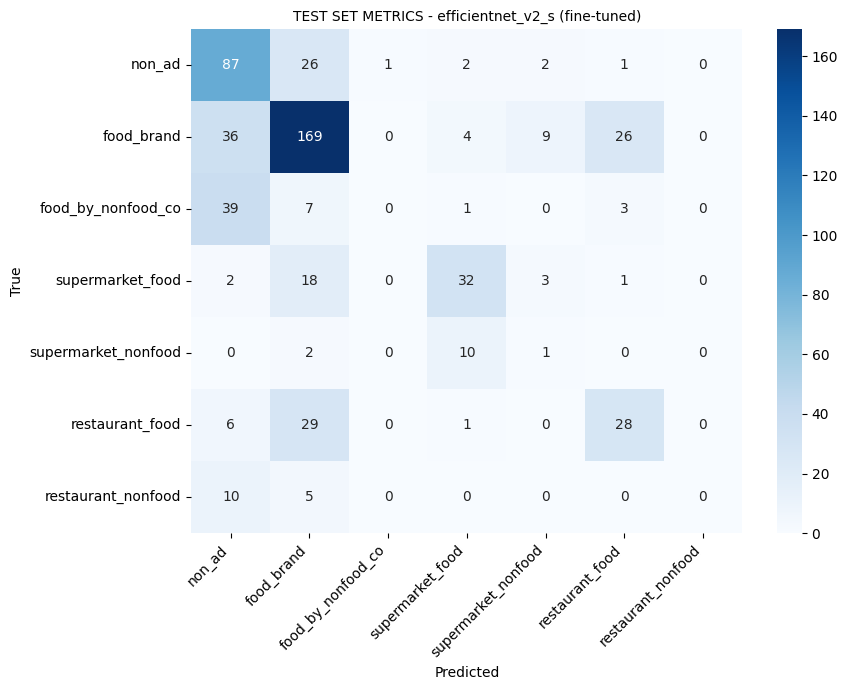

In [10]:
# =====================================================================
# Set FINETUNE = True for end-to-end fine-tuning (backbone + head).
# Set FINETUNE = False for frozen-embeddings + head-only training.
# =====================================================================
FINETUNE = True

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
training_started = time.perf_counter()
if FINETUNE:
    # Head warm-up on cached embeddings, then fine-tune the top of the backbone (see fine_tune()).
    print(f"Fine-tuning mode: {BACKBONE}")
    backbone_model, transform, feature_dim = build_backbone(BACKBONE, DEVICE)
    ft_train_loader, ft_train_eval_loader, ft_val_loader, ft_test_loader = build_finetune_loaders(
        train_df, val_df, test_df, transform
    )
    model, history, best_val_f1 = fine_tune(
        backbone_model, BACKBONE,
        ft_train_loader, ft_train_eval_loader, ft_val_loader,
        num_classes=NUM_CLASSES, feature_dim=feature_dim,
    )
    eval_val_loader, eval_test_loader = ft_val_loader, ft_test_loader
    predict_fn = lambda path: predict_single_image_finetuned(path, model, transform)
else:
    print(f"Extracting frozen embeddings: {BACKBONE}")
    extractor = VisionFeatureExtractor(backbone=BACKBONE)
    train_embeddings = build_embeddings(train_df["image_path"].tolist(), extractor, description="Train embeddings")
    val_embeddings = build_embeddings(val_df["image_path"].tolist(), extractor, description="Validation embeddings")
    test_embeddings = build_embeddings(test_df["image_path"].tolist(), extractor, description="Test embeddings")
    train_loader, val_loader, test_loader = build_loaders(
        train_embeddings, Y["train"], val_embeddings, Y["val"], test_embeddings, Y["test"]
    )
    model, history, best_val_f1 = train_head(
        train_loader, val_loader, Y["train"], num_classes=NUM_CLASSES, input_dim=train_embeddings.shape[1],
    )
    eval_val_loader, eval_test_loader = val_loader, test_loader
    predict_fn = lambda path: predict_single_image(path, model, extractor)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
training_seconds = time.perf_counter() - training_started
print(f"\nBest validation macro-F1: {best_val_f1:.4f}")
print(f"Training time (includes backbone loading and embedding extraction): {training_seconds:.1f} s")

val_metrics, _, _, _ = evaluate(model, eval_val_loader)
test_started = time.perf_counter()
test_metrics, test_true, test_probs, test_pred = evaluate(model, eval_test_loader)
test_seconds = time.perf_counter() - test_started
assert np.array_equal(test_true, Y["test"])

MODE = "fine-tuned" if FINETUNE else "frozen backbone + head"
per_class = report_configuration(
    f"TEST SET METRICS - {BACKBONE} ({MODE})", test_true, test_pred, test_metrics,
    extra_lines=[f"Validation macro-F1 (selection metric): {val_metrics['macro_f1']:.4f}",
                 f"Test inference time: {test_seconds:.2f} s"],
)

## Training curves

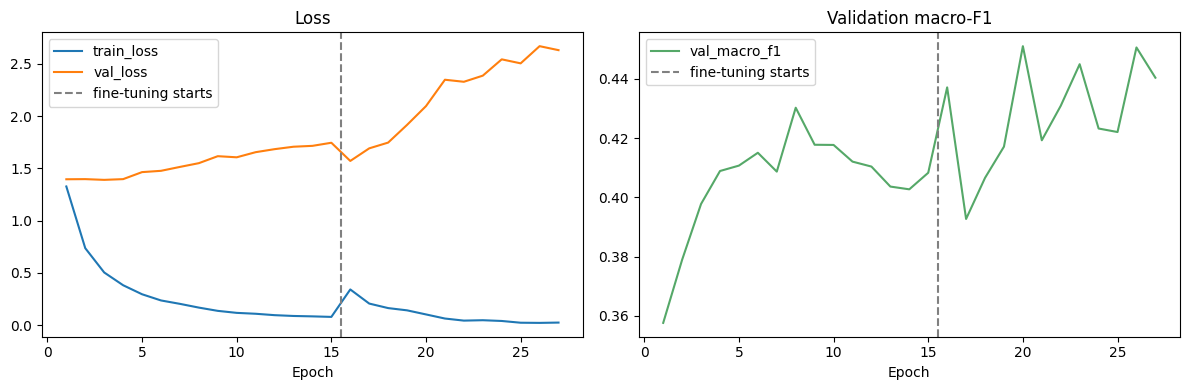

In [11]:
metric_frame = pd.DataFrame(history)
fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(metric_frame["epoch"], metric_frame["train_loss"], label="train_loss")
ax_loss.plot(metric_frame["epoch"], metric_frame["val_loss"], label="val_loss")
ax_loss.set_title("Loss")
ax_f1.plot(metric_frame["epoch"], metric_frame["val_macro_f1"], label="val_macro_f1", color="#55A868")
ax_f1.set_title("Validation macro-F1")
if "stage" in metric_frame and (metric_frame["stage"] == 2).any():
    first_stage2 = metric_frame.loc[metric_frame["stage"] == 2, "epoch"].min()
    for ax in (ax_loss, ax_f1):
        ax.axvline(first_stage2 - 0.5, color="gray", linestyle="--", label="fine-tuning starts")
for ax in (ax_loss, ax_f1):
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## Real images test

One seeded random test image per class with the top-3 class probabilities (softmax outputs, not calibrated).

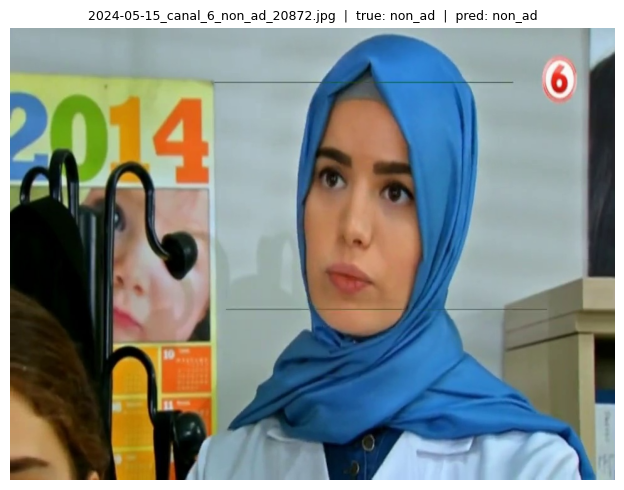

True: non_ad (tip 0)  Predicted: non_ad  Correct: True
  - non_ad              : 1.000
  - food_brand          : 0.000
  - restaurant_food     : 0.000



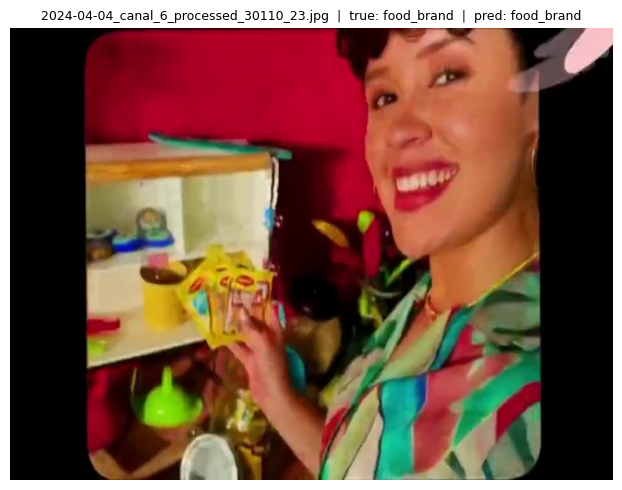

True: food_brand (tip 2)  Predicted: food_brand  Correct: True
  - food_brand          : 0.884
  - non_ad              : 0.057
  - supermarket_food    : 0.053



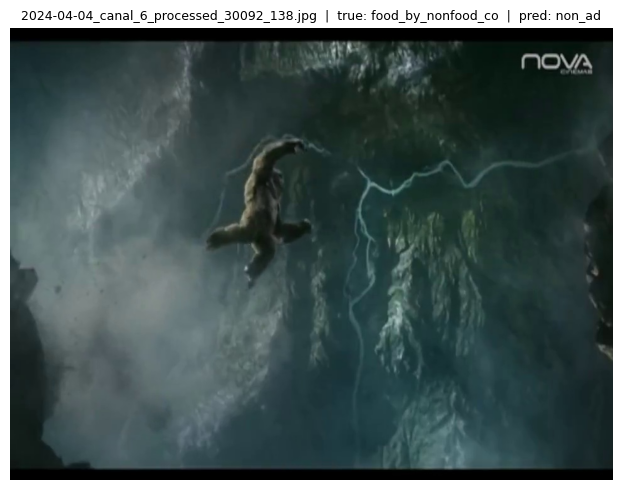

True: food_by_nonfood_co (tip 3)  Predicted: non_ad  Correct: False
  - non_ad              : 0.818
  - food_brand          : 0.173
  - supermarket_nonfood : 0.005



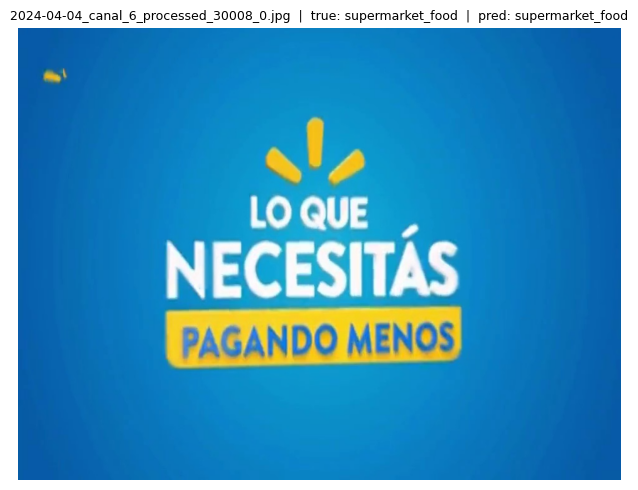

True: supermarket_food (tip 5)  Predicted: supermarket_food  Correct: True
  - supermarket_food    : 1.000
  - supermarket_nonfood : 0.000
  - restaurant_food     : 0.000



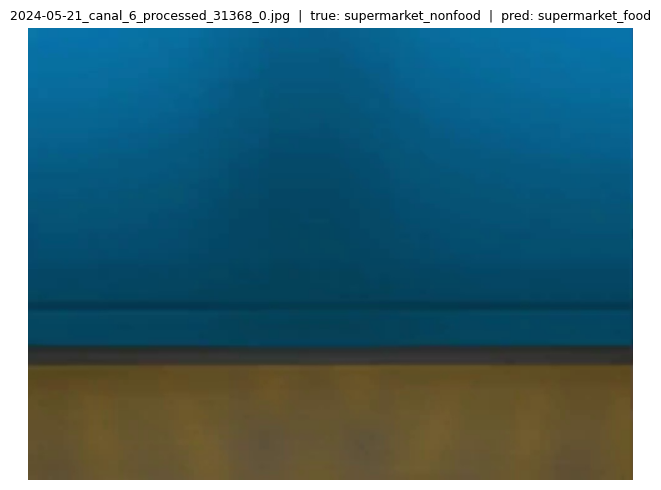

True: supermarket_nonfood (tip 6)  Predicted: supermarket_food  Correct: False
  - supermarket_food    : 0.318
  - non_ad              : 0.309
  - supermarket_nonfood : 0.299



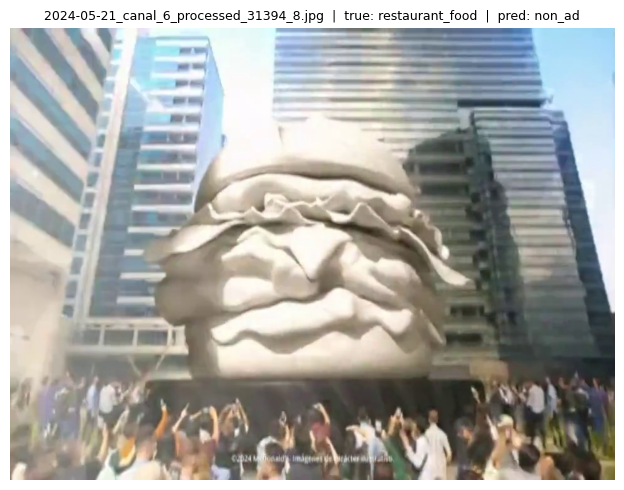

True: restaurant_food (tip 7)  Predicted: non_ad  Correct: False
  - non_ad              : 0.701
  - food_brand          : 0.267
  - food_by_nonfood_co  : 0.017



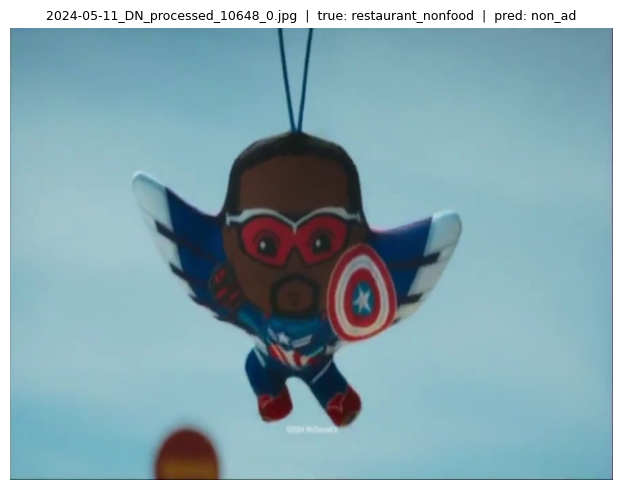

True: restaurant_nonfood (tip 8)  Predicted: non_ad  Correct: False
  - non_ad              : 0.989
  - food_brand          : 0.011
  - supermarket_food    : 0.000



In [12]:
# One seeded random test image per class. Probabilities come from the test pass above;
# predict_fn(path) returns the same class probabilities for any other image.
for idx in sample_test_indices(per_class=1):
    row = test_df.loc[idx]
    probs = test_probs[idx]
    pred = int(probs.argmax())
    show_image(row["image_path"], f"{row['image_name']}  |  true: {row['class_name']}  |  pred: {CLASS_NAMES[pred]}")
    print(f"True: {row['class_name']} (tip {row['tip']})  Predicted: {CLASS_NAMES[pred]}  Correct: {pred == row['y']}")
    for i in np.argsort(-probs)[:3]:
        print(f"  - {CLASS_NAMES[i]:<20}: {probs[i]:.3f}")
    print()

## Export results

Writes the split manifest, training history, per-class test metrics, test predictions and run metadata to `runs/cnn/`.

In [13]:
RESULTS_DIR = Path.cwd() / "runs" / "cnn"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

save_split_manifest(RESULTS_DIR)
pd.DataFrame(history).to_csv(RESULTS_DIR / "history.csv", index=False)
per_class.to_csv(RESULTS_DIR / "test_per_class.csv", index=False)
test_df[["image_name", "tip", "class_name", "group"]].assign(
    predicted=[CLASS_NAMES[i] for i in test_pred],
    **{f"prob_{name}": test_probs[:, i] for i, name in enumerate(CLASS_NAMES)},
).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

with open(RESULTS_DIR / "run_metadata.json", "w") as f:
    json.dump({
        **environment_metadata(),
        "strategy": "cnn",
        "backbone": BACKBONE,
        "finetune": FINETUNE,
        "loss": "cross-entropy with class weights sqrt(N / (K * n_c))",
        "early_stopping": "validation macro-F1, patience 7",
        "epochs_run": len(history),
        "best_val_macro_f1": best_val_f1,
        "val_metrics": val_metrics,
        "test_metrics": test_metrics,
        "training_seconds": training_seconds,
        "test_inference_seconds": test_seconds,
    }, f, indent=2)

print(f"Results written to {RESULTS_DIR}")
for path in sorted(RESULTS_DIR.iterdir()):
    print(f"  - {path.name}")
download_results(RESULTS_DIR, f"cnn_multiclass_results_{BACKBONE}")

Results written to /content/runs/cnn
  - history.csv
  - run_metadata.json
  - split_manifest.csv
  - test_per_class.csv
  - test_predictions.csv
Archive: /content/cnn_multiclass_results_efficientnet_v2_s.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>